### ASEN 6337 Homework 3: Classification using Fisher LDA

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import urllib.request
from scipy.linalg import eigh
from IPython.display import display, Markdown

plt.rcParams["figure.dpi"] = 110
class_names = ["Forest", "AnnualCrop", "Residential"]
colors = ["forestgreen", "darkorange", "royalblue"]
markers = ["o", "^", "s"]

output_folder = Path("HW3_results")
output_folder.mkdir(exist_ok=True)


Downlaoding the dataset

In [2]:
train_url = "https://github.com/adwait39/eurosat-competition/releases/download/v1.0-data/train.npz"
train_path = Path("train.npz")
expected_bytes = 1446285824

if not train_path.exists() or train_path.stat().st_size != expected_bytes:
    print("Downloading train.npz, about 1.45 GB. Please wait...")
    urllib.request.urlretrieve(train_url, train_path)
else:
    print("Using the existing train.npz file.")

if train_path.stat().st_size != expected_bytes:
    raise ValueError("The download is incomplete. Run this cell again.")

with np.load(train_path, allow_pickle=False) as data:
    patches = data["X"]
    all_labels = data["y"]
    all_class_names = data["classes"].astype(str)
    band_names = data["bands"].astype(str).tolist()
    wavelength_nm = data["wavelength_nm"]

if patches.shape != (18900, 64, 64, 13):
    raise ValueError("Unexpected training image shape.")
if all_labels.shape != (18900,) or len(all_class_names) != 10:
    raise ValueError("Unexpected training labels or class names.")
if np.any(all_labels < 0) or np.any(all_labels >= len(all_class_names)):
    raise ValueError("A label does not match the class list.")

print("Image array shape:", patches.shape)
print("Image data type:", patches.dtype)
print("Classes:", all_class_names)
display(pd.DataFrame({"Band": band_names, "Wavelength (nm)": wavelength_nm}))


Image array shape: (18900, 64, 64, 13)
Image data type: uint16
Classes: ['AnnualCrop' 'Forest' 'HerbaceousVegetation' 'Highway' 'Industrial'
 'Pasture' 'PermanentCrop' 'Residential' 'River' 'SeaLake']


,Band,Wavelength (nm)
0,B01,443
1,B02,490
2,B03,560
3,B04,665
4,B05,705
5,B06,740
6,B07,783
7,B08,842
8,B8A,865
9,B09,945


I will use Forest as class 0, AnnualCrop as class 1, and Residential as class 2

In [3]:
selection_seed = 42
split_seed = 24

np.random.seed(selection_seed)
selected_indices = []
y = []
available_rows = []

for class_number in range(3):
    name = class_names[class_number]
    original_label = np.where(all_class_names == name)[0][0]
    available = np.where(all_labels == original_label)[0]
    available_rows.append([name, len(available)])

    if len(available) < 500:
        raise ValueError("Fewer than 500 images found for " + name)

    chosen = np.random.choice(available, 500, replace=False)
    selected_indices.extend(chosen)
    y.extend([class_number] * 500)

selected_indices = np.array(selected_indices)
y = np.array(y)
assert len(np.unique(selected_indices)) == 1500

display(pd.DataFrame(available_rows, columns=["Class", "Available training images"]))
print("Selected images:", len(selected_indices))
print("Selection seed:", selection_seed)
print("Split seed:", split_seed)


,Class,Available training images
0,Forest,2100
1,AnnualCrop,2100
2,Residential,2100


Selected images: 1500
Selection seed: 42
Split seed: 24


In [4]:
X = np.zeros((len(selected_indices), 13))

for i in range(len(selected_indices)):
    source_index = selected_indices[i]
    image = patches[source_index]
    X[i] = image.mean(axis=(0, 1))

    if (i + 1) % 500 == 0:
        print("Images processed:", i + 1)

if not np.isfinite(X).all():
    raise ValueError("Missing or infinite band means found.")

# Keep one image per class for a small visual example later.
example_images = []
for k in range(3):
    position = np.where(y == k)[0][0]
    example_images.append(patches[selected_indices[position]].copy())

# The large image array is no longer needed after calculating the means.
del image, patches

feature_table = pd.DataFrame(X, columns=band_names)
feature_table["Class"] = [class_names[label] for label in y]
feature_table["Source index"] = selected_indices

print("Feature table shape:", X.shape)
print("Missing or infinite values:", np.sum(~np.isfinite(X)))
display(feature_table.head())


Images processed: 500
Images processed: 1000
Images processed: 1500
Feature table shape: (1500, 13)
Missing or infinite values: 0


,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12,Class,Source index
0,1186.240479,873.770020,720.762939,424.625244,716.522461,2149.862061,2774.701660,2710.619873,3056.372314,783.937012,10.459473,1419.761963,571.371582,Forest,9460
1,1195.378906,873.224121,699.416992,421.110352,708.191650,2059.545410,2722.688721,2643.229736,3044.780029,639.698730,10.489990,1400.116211,522.096680,Forest,10552
2,1123.429443,798.558350,671.409668,379.963623,737.539307,2196.827637,2853.967773,2748.380127,3173.471191,768.457764,9.042480,1395.016357,538.903320,Forest,555
3,993.839844,770.571533,978.019287,501.231689,1444.466797,2738.368652,3060.675293,3071.447998,3360.983154,1634.906006,16.142578,1572.875732,735.699951,Forest,11836
4,1186.509521,856.073730,693.657715,392.348145,754.604492,2276.297363,3050.800293,3050.928223,3558.534424,785.907959,9.620117,1502.117432,552.178711,Forest,6066


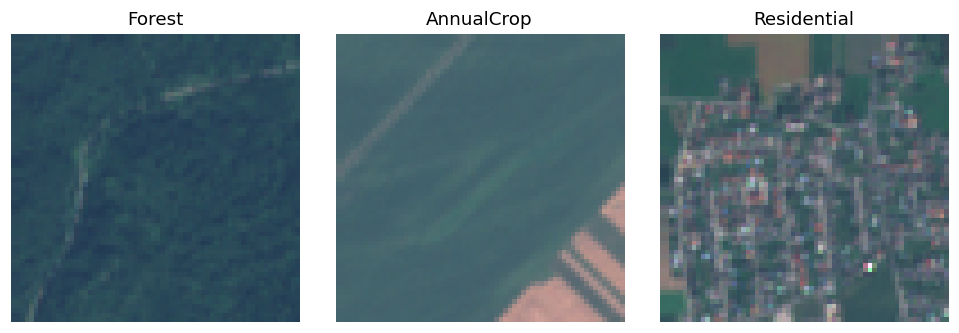

In [5]:
rgb_bands = [band_names.index("B04"), band_names.index("B03"), band_names.index("B02")]
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for k in range(3):
    rgb = example_images[k][:, :, rgb_bands].astype(float)
    rgb = np.clip(rgb / 2500.0, 0, 1)
    axes[k].imshow(rgb, interpolation="nearest")
    axes[k].set_title(class_names[k])
    axes[k].axis("off")
plt.tight_layout()
plt.savefig(output_folder / "example_images.png", dpi=160)
plt.show()

### MAking Test and Training Sets

For each class, we shuffle its 500 selected images. The first 350 go into training and the remaining 150 go into testing. This gives 1,050 training images and 450 test images. The sets do not share source image indices.

In [6]:
np.random.seed(split_seed)
train_indices = []
test_indices = []

for class_number in range(3):
    indices = np.where(y == class_number)[0]
    np.random.shuffle(indices)
    train_indices.extend(indices[:350])
    test_indices.extend(indices[350:])

train_indices = np.array(train_indices)
test_indices = np.array(test_indices)

X_train = X[train_indices]
X_test = X[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

assert len(set(train_indices) & set(test_indices)) == 0

split_rows = []
for k in range(3):
    split_rows.append([
        class_names[k], np.sum(y == k),
        np.sum(y_train == k), np.sum(y_test == k)
    ])

split_table = pd.DataFrame(
    split_rows, columns=["Class", "Selected", "Training", "Testing"]
)
display(split_table)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# Save the exact source indices and split so that the experiment can be repeated.
manifest = pd.DataFrame({
    "Source index in train.npz": selected_indices,
    "Class": [class_names[label] for label in y]
})
manifest["Split"] = "test"
manifest.loc[train_indices, "Split"] = "train"
manifest["Selection seed"] = selection_seed
manifest["Split seed"] = split_seed
manifest.to_csv(output_folder / "selected_images_and_split.csv", index=False)
feature_table.to_csv(output_folder / "band_means.csv", index=False)


,Class,Selected,Training,Testing
0,Forest,500,350,150
1,AnnualCrop,500,350,150
2,Residential,500,350,150


Training shape: (1050, 13)
Testing shape: (450, 13)


### Calculate the scatter matrices

### Question 1

Fisher LDA looks for directions where the class averages are far apart compared with the variation inside each class. We calculate everything below using only the training data.

The within-class scatter matrix describes the spread around each class average:

$$S_w = \sum_{k=1}^{3}\sum_{i \in k}(x_i-m_k)(x_i-m_k)^T.$$

The between-class scatter matrix describes how far the class averages are from the overall average:

$$S_b = \sum_{k=1}^{3}n_k(m_k-m)(m_k-m)^T.$$

Here, $m_k$ is a class average, $m$ is the overall training average, and $n_k=350$. Both matrices have shape 13 × 13. In the code, `@` means matrix multiplication, and `np.outer` forms a matrix from the products of a vector's entries.

In [7]:
overall_mean = X_train.mean(axis=0)
Sw = np.zeros((13, 13))
Sb = np.zeros((13, 13))

for k in range(3):
    class_data = X_train[y_train == k]
    class_mean = class_data.mean(axis=0)

    difference = class_data - class_mean
    Sw += difference.T @ difference

    mean_difference = class_mean - overall_mean
    Sb += len(class_data) * np.outer(mean_difference, mean_difference)

print("Sw shape:", Sw.shape)
print("Sb shape:", Sb.shape)


Sw shape: (13, 13)
Sb shape: (13, 13)


## Find the two Fisher directions
### Question 1(a)

For three classes, we expect **at most two nonzero Fisher directions**, because the maximum is the number of classes minus one: $3-1=2$. The three class averages provide at most two independent differences from their overall average.

Solving:

$$S_b w = \lambda S_w w.$$

The vector $w$ gives a direction, and $\lambda$ measures the separation between classes relative to the spread within classes along that direction. We keep the two eigenvectors with the largest eigenvalues. These become the columns of `W`.


In [8]:
eigenvalues, eigenvectors = eigh(Sb, Sw)
order = np.argsort(eigenvalues)[::-1]
W = eigenvectors[:, order[:2]]

print("Two largest eigenvalues:", eigenvalues[order[:2]])
print("Projection matrix shape:", W.shape)


Two largest eigenvalues: [2.51094327 0.91133853]
Projection matrix shape: (13, 2)


## Project the data and plot the two coordinates
### Questions 1(b) and 1(c)

We subtract the same training average from both sets, then multiply by `W`:

$$Z_{train}=(X_{train}-m)W, \qquad Z_{test}=(X_{test}-m)W.$$

Each image now has two numbers instead of 13. Each point in the plots represents one image, and its color and symbol show its true class. Test labels are used to color the test plot, but were not used to calculate `W`.


Projected training shape: (1050, 2)
Projected test shape: (450, 2)


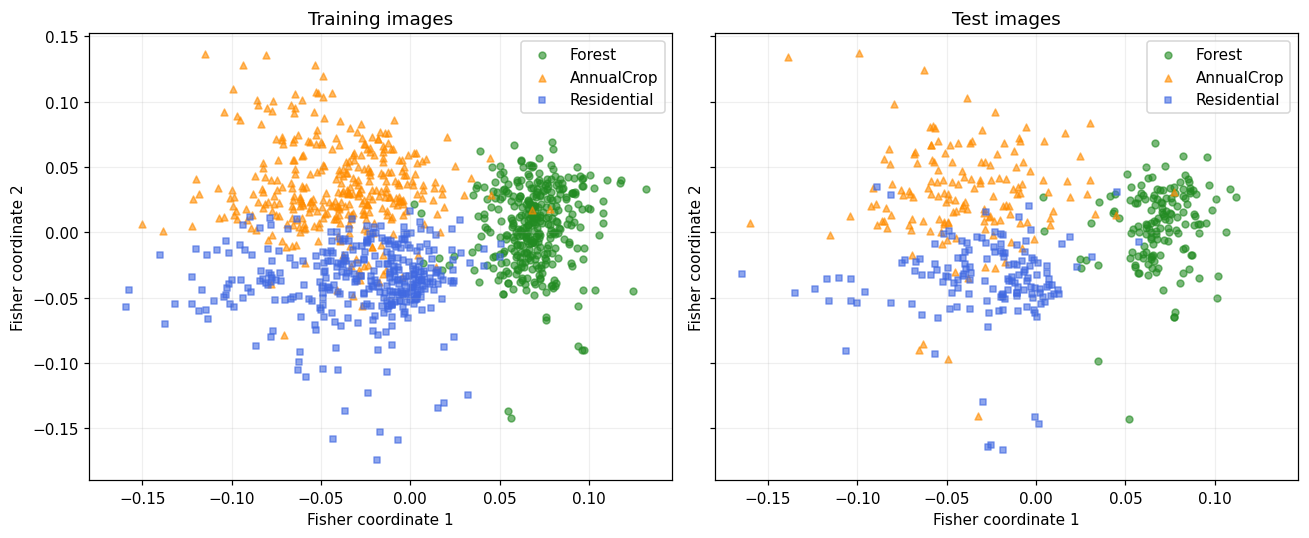

In [9]:
Z_train = (X_train - overall_mean) @ W
Z_test = (X_test - overall_mean) @ W

print("Projected training shape:", Z_train.shape)
print("Projected test shape:", Z_test.shape)

colors = ["forestgreen", "darkorange", "royalblue"]
markers = ["o", "^", "s"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for k in range(3):
    axes[0].scatter(Z_train[y_train == k, 0], Z_train[y_train == k, 1],
                    color=colors[k], marker=markers[k], alpha=0.6, s=20,
                    label=class_names[k])
    axes[1].scatter(Z_test[y_test == k, 0], Z_test[y_test == k, 1],
                    color=colors[k], marker=markers[k], alpha=0.6, s=20,
                    label=class_names[k])

axes[0].set_title("Training images")
axes[1].set_title("Test images")
for ax in axes:
    ax.set_xlabel("Fisher coordinate 1")
    ax.set_ylabel("Fisher coordinate 2")
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()


## Predict the test classes

The projection gives two coordinates, but we still need a rule to predict a class. we calculate the average position of each training class in Fisher space. For each test point, we predict the class whose average position is nearest.

The directions returned by `eigh(Sb, Sw)` are scaled so the combined within-class scatter in the projected coordinates is the identity matrix. With the equal training class sizes used here, nearest-center classification is therefore consistent with the shared-covariance LDA rule. We keep the solver's scaling of the eigenvectors.


In [10]:
centers = np.zeros((3, 2))

for k in range(3):
    centers[k] = Z_train[y_train == k].mean(axis=0)

distances = np.zeros((len(Z_test), 3))

for k in range(3):
    difference = Z_test - centers[k]
    distances[:, k] = np.sum(difference ** 2, axis=1)

y_pred = np.argmin(distances, axis=1)


## Calculate the confusion matrix, accuracy, and kappa
### Question 2(b)

In the confusion matrix, rows are the true classes and columns are the predicted classes. The diagonal entries are correct predictions. Each row contains 150 test images.

Accuracy is the number of correct predictions divided by the number of test images:

$$p_o=\frac{\sum_k R_{kk}}{N}.$$

Expected agreement uses the row totals $R_{k+}$ and column totals $R_{+k}$:

$$p_e=\frac{\sum_k R_{k+}R_{+k}}{N^2}, \qquad
\kappa=\frac{p_o-p_e}{1-p_e}.$$

Here, $N=450$. Kappa is 1 for perfect agreement and 0 when agreement equals this chance reference. It can also be negative. I calculate both measures directly from the matrix.


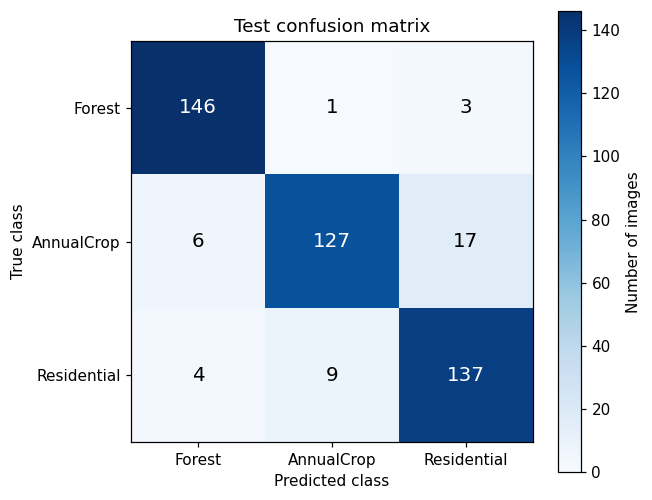

Correct predictions: 410 out of 450
Overall test accuracy (%): 91.11
Expected agreement: 0.3333
Kappa: 0.8667


In [11]:
confusion = np.zeros((3, 3), dtype=int)

for i in range(len(y_test)):
    confusion[y_test[i], y_pred[i]] += 1

fig, ax = plt.subplots(figsize=(6, 5))
picture = ax.imshow(confusion, cmap="Blues", vmin=0)

for row in range(3):
    for column in range(3):
        color = "white" if confusion[row, column] > confusion.max() / 2 else "black"
        ax.text(column, row, str(confusion[row, column]),
                ha="center", va="center", color=color, fontsize=13)

ax.set_xticks(range(3), class_names)
ax.set_yticks(range(3), class_names)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Test confusion matrix")
fig.colorbar(picture, ax=ax, label="Number of images")
plt.tight_layout()
plt.show()

N_test = confusion.sum()
po = np.trace(confusion) / N_test
row_totals = confusion.sum(axis=1)
column_totals = confusion.sum(axis=0)
pe = np.sum(row_totals * column_totals) / N_test ** 2
kappa = (po - pe) / (1 - pe)

print("Correct predictions:", np.trace(confusion), "out of", N_test)
print("Overall test accuracy (%):", round(100 * po, 2))
print("Expected agreement:", round(pe, 4))
print("Kappa:", round(kappa, 4))


## Discussion
Questions 2(a) and 2(b)
The two-dimensional Fisher representation separated the three classes reasonably well. Forest formed a mostly separate group, while AnnualCrop and Residential overlapped more. The test plot showed a similar general pattern to the training plot. This suggests that the two coordinates retained useful information for classifying images, although the separation was not perfect.

With selection seed 42 and split seed 24, the classifier correctly predicted 410 of 450 test images, giving 91.11% overall accuracy and a kappa coefficient of 0.8667. Forest had 146 correct predictions, AnnualCrop had 127, and Residential had 137, out of 150 images per class.

AnnualCrop and Residential were confused most often. There were 17 AnnualCrop images predicted as Residential and 9 Residential images predicted as AnnualCrop. These 26 errors accounted for most of the 40 mistakes, consistent with their overlap in the plot. Using band means makes each image simple to describe, but removes texture and spatial arrangement that could help distinguish similar images. These results apply to this three-class sample and split.